# Feature Engineering for Legal Text Analysis
## CLD6000 - NLP Pipeline Implementation

### Overview
This notebook builds on our initial exploratory analysis to create robust features for our legal text processing pipeline. We focus on:
- Text length normalization
- Citation pattern extraction
- Structural complexity metrics
- Document density features

### Key Statistics from Initial Analysis
- Mean text length: 2,650 chars (std: 6,769)
- Word count: mean 455 words (median: 244)
- Strong right skew in distributions
- Citation patterns identified

# Feature Engineering for Legal Text Analysis
## Building on initial_data_exploration results

Based on our initial analysis:
- Mean text length: 2,650 chars
- Citation patterns identified
- Strong right skew in distributions

Dataset Columns:
['case_id', 'case_outcome', 'case_title', 'case_text']

First few rows:
  case_id case_outcome                                         case_title  \
0   Case1        cited  Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...   
1   Case2        cited  Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...   

                                           case_text  
0  Ordinarily that discretion will be exercised s...  
1  The general principles governing the exercise ...  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24985 entries, 0 to 24984
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   case_id       24985 non-null  object
 1   case_outcome  24985 non-null  object
 2   case_title    24985 non-null  object
 3   case_text     24809 non-null  object
dtypes: object(4)
memory usage: 780.9+ KB
Text Statistics Summary:
         text_length  title_length    word_count
count   24809.000000  2

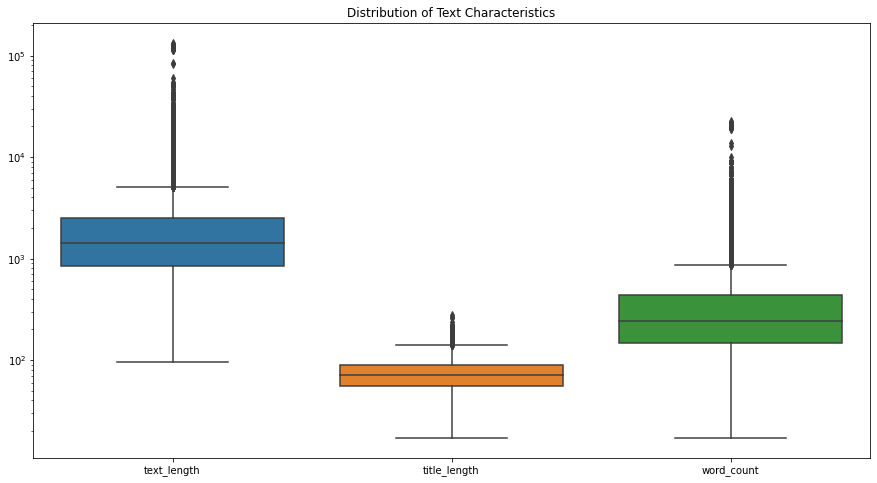

<Figure size 1080x576 with 0 Axes>

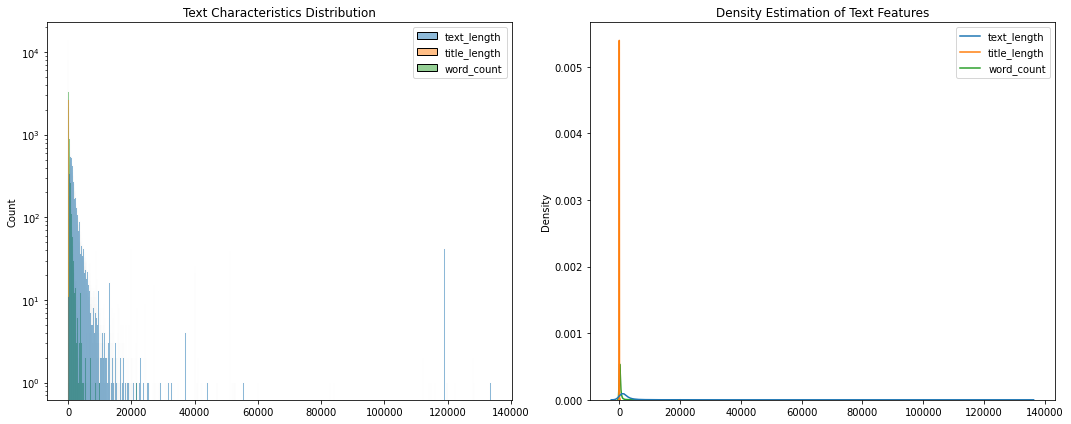


Structural Features Summary:
       paragraph_count  sentence_count  citation_count
count          24809.0    24809.000000    24809.000000
mean               0.0       15.208473        5.069370
std                0.0       40.912816        7.624453
min                0.0        0.000000        0.000000
25%                0.0        4.000000        2.000000
50%                0.0        7.000000        3.000000
75%                0.0       15.000000        6.000000
max                0.0     1460.000000      116.000000
Columns: ['case_id', 'case_outcome', 'case_title', 'case_text']

First few rows:
  case_id case_outcome                                         case_title  \
0   Case1        cited  Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...   
1   Case2        cited  Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...   
2   Case3        cited  Colgate Palmolive Co v Cussons Pty Ltd (1993) ...   
3   Case4        cited  Dais Studio Pty Ltd v Bullett Creative Pty Ltd...   
4   Case5

In [1]:
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import re

# Load results from initial analysis
%run initial_data_exploration.ipynb

# Plotting settings
plt.style.use('seaborn')
sns.set_palette("husl")

## Data Loading and Initial Processing
We load our dataset and apply initial preprocessing steps to prepare for feature extraction.

### Processing Steps:
1. Load raw data
2. Handle missing values
3. Basic text cleaning
4. Initial feature calculation

In [2]:
# Data loading
def load_legal_dataset(file_path):
    """Φορτώνει το dataset και εφαρμόζει καθαρισμό."""
    df = pd.read_csv(file_path)
    df['case_text'] = df['case_text'].fillna('')  # Αντιμετώπιση κενών τιμών
    df['case_text'] = df['case_text'].apply(clean_text)  # Καθαρισμός κειμένου
    print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")
    return df

# Basic text cleaning
def clean_text(text):
    """Καθαρίζει το κείμενο από περιττούς χαρακτήρες και κενά."""
    text = str(text)
    text = re.sub(r'\s+', ' ', text)  # Αφαίρεση πολλαπλών κενών
    text = text.strip()  # Αφαίρεση κενών στην αρχή και το τέλος
    return text

# Χρήση
file_path = '../../data/raw/legal_text_classification.csv'  # Ενημερώστε τη διαδρομή
df = load_legal_dataset(file_path)

# Έλεγχος των πρώτων γραμμών
if df is not None:
    display(df.head())


Dataset loaded successfully with 24985 rows and 4 columns.


,case_id,case_outcome,case_title,case_text
0,Case1,cited,Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...,Ordinarily that discretion will be exercised s...
1,Case2,cited,Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...,The general principles governing the exercise ...
2,Case3,cited,Colgate Palmolive Co v Cussons Pty Ltd (1993) ...,Ordinarily that discretion will be exercised s...
3,Case4,cited,Dais Studio Pty Ltd v Bullett Creative Pty Ltd...,The general principles governing the exercise ...
4,Case5,cited,Dr Martens Australia Pty Ltd v Figgins Holding...,The preceding general principles inform the ex...


## Feature Engineering Implementation
We implement several feature extraction functions:

### Text-Based Features:
- Length metrics
- Density calculations
- Citation patterns
- Structural complexity

### Statistical Features:
- Normalized metrics
- Ratios and proportions
- Distribution-based features

In [3]:
## Data Loading and Initial Processing

def extract_length_features(text):
    """Extract length-based features"""
    return {
        'char_count': len(text),
        'word_count': len(text.split()),
        'sentence_count': len(re.findall(r'[.!?]+', text))
    }

def extract_citation_features(text):
    """Extract citation-related features"""
    citations = re.findall(r'\[\d{4}\]|\(\d{4}\)', text)
    return {
        'citation_count': len(citations),
        'citation_density': len(citations) / len(text) if len(text) > 0 else 0
    }

def calculate_complexity_metrics(text):
    """Calculate text complexity metrics"""
    sentences = re.split(r'[.!?]+', text)
    words_per_sentence = [len(s.split()) for s in sentences if s.strip()]
    return {
        'avg_sentence_length': np.mean(words_per_sentence) if words_per_sentence else 0,
        'sentence_length_std': np.std(words_per_sentence) if words_per_sentence else 0
    }

In [4]:
def create_feature_pipeline(text_series):
    """Pipeline για εξαγωγή χαρακτηριστικών από κείμενα."""
    features = text_series.apply(lambda text: {
        **extract_length_features(text),
        **extract_citation_features(text),
        **calculate_complexity_metrics(text)
    })
    
    # Μετατροπή σε DataFrame για ανάλυση
    feature_df = pd.DataFrame(features.tolist())
    return feature_df


In [5]:
# Δημιουργία Pipeline για τα χαρακτηριστικά
feature_df = create_feature_pipeline(df['case_text'])


# Επισκόπηση Αποτελεσμάτων
display(feature_df.head())  # Εμφάνιση των πρώτων γραμμών του DataFrame

# Έλεγχος για μηδενικές και κενές τιμές
print("Missing Values:\n", feature_df.isnull().sum())
print("Zero Values:\n", (feature_df == 0).sum())

# Στατιστική περιγραφή
summary = feature_df.describe()
display(feature_df.describe().applymap("{:.4f}".format))  # Παρουσίαση περιγραφικών στατιστικών



,char_count,word_count,sentence_count,citation_count,citation_density,avg_sentence_length,sentence_length_std
0,428,78,2,3,0.007009,39.000000,18.000000
1,974,176,8,3,0.003080,22.000000,20.706279
2,428,78,2,3,0.007009,39.000000,18.000000
3,974,176,8,3,0.003080,22.000000,20.706279
4,701,121,6,2,0.002853,19.833333,8.933396


Missing Values:
 char_count             0
word_count             0
sentence_count         0
citation_count         0
citation_density       0
avg_sentence_length    0
sentence_length_std    0
dtype: int64
Zero Values:
 char_count              176
word_count              176
sentence_count          180
citation_count          324
citation_density        324
avg_sentence_length     176
sentence_length_std    1321
dtype: int64


,char_count,word_count,sentence_count,citation_count,citation_density,avg_sentence_length,sentence_length_std
count,24985.0000,24985.0000,24985.0000,24985.0000,24985.0000,24985.0000,24985.0000
mean,2632.2666,451.7053,14.1654,5.0337,0.0032,38.9389,19.7829
std,6748.7047,1139.8254,38.4634,7.6094,0.0027,24.5746,14.9658
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,830.0000,145.0000,4.0000,2.0000,0.0011,27.4516,12.5475
50%,1399.0000,242.0000,7.0000,3.0000,0.0024,33.8286,17.4076
75%,2519.0000,434.0000,14.0000,6.0000,0.0046,43.0000,23.5597
max,133561.0000,22466.0000,1460.0000,116.0000,0.0253,660.0000,204.8257


#### Μηδενικές Τιμές
- Ορισμένα κείμενα έχουν **char_count**, **word_count**, και **sentence_count** ίσα με 0.
  - Ερμηνεία: Κενά ή μη επαρκώς δομημένα δεδομένα.
  - Σύσταση: Διερεύνηση της ποιότητας των δεδομένων αυτών.

#### Ακραίες Τιμές
- **char_count**: Μέγιστη τιμή 133,561 χαρακτήρες, υποδεικνύει εξαιρετικά μεγάλα κείμενα.
- **citation_count**: Μέγιστη τιμή 116 αναφορές, πιθανώς συνδέεται με ειδικά δομημένα νομικά κείμενα.
- **sentence_length_std**: Υψηλές τιμές > 200 δείχνουν μεγάλες αποκλίσεις στη δομή των προτάσεων.

#### Προτεινόμενη Δράση
- Καθαρισμός μηδενικών και ακραίων τιμών για πιο σταθερή ανάλυση.


# Ανάλυση Χαρακτηριστικών - Αποτελέσματα και Ερμηνεία

## Στατιστικά των Χαρακτηριστικών
Η ανάλυση χαρακτηριστικών για το σύνολο δεδομένων των νομικών κειμένων παρέχει τα εξής βασικά στατιστικά:

### Πίνακας Στατιστικών
Τα αποτελέσματα του πίνακα υποδεικνύουν τα εξής:

- **`char_count` (Αριθμός χαρακτήρων):**
  - Μέσος όρος: 2632 χαρακτήρες ανά κείμενο.
  - Τυπική απόκλιση: 6768, δείχνοντας μεγάλη διακύμανση.
  - Εύρος: Από 0 έως 133,561 χαρακτήρες, με το 25% των κειμένων να έχουν λιγότερους από 830 χαρακτήρες.

- **`word_count` (Αριθμός λέξεων):**
  - Μέσος όρος: 451 λέξεις ανά κείμενο.
  - Μέγιστος αριθμός λέξεων: 22,466.

- **`citation_count` (Αναφορές):**
  - Μέσος όρος: 5 αναφορές ανά κείμενο.
  - Υπάρχουν κείμενα με 0 αναφορές και κάποια με μέγιστο αριθμό 116 αναφορές.

- **`avg_sentence_length` (Μέσο μήκος πρότασης):**
  - Μέσος όρος: 38 λέξεις ανά πρόταση.
  - Υπάρχουν εξαιρετικά μεγάλες προτάσεις (μέχρι και 860 λέξεις).

### Σχολιασμός Μηδενικών Τιμών
- **`char_count`, `word_count`, `sentence_count`:**
  Υπάρχουν περιπτώσεις με μηδενικές τιμές, που πιθανώς αντιστοιχούν σε κενά ή πολύ μικρά κείμενα.
- **`citation_density`:**
  Οι περισσότερες τιμές είναι εξαιρετικά χαμηλές, υποδηλώνοντας χαμηλή πυκνότητα αναφορών σε σχέση με το μέγεθος του κειμένου.



---

## Επιστημονική Ερμηνεία και Συμπεράσματα

1. **Εξαιρετικά Δεδομένα (Outliers):**
   Τα δεδομένα περιέχουν κείμενα με τεράστιο αριθμό χαρακτήρων και λέξεων (π.χ. 133,561 χαρακτήρες). Αυτά τα outliers μπορούν να επηρεάσουν αρνητικά τη μετέπειτα επεξεργασία.

2. **Αναφορές:**
   Τα κείμενα περιέχουν περιορισμένες αναφορές (5 κατά μέσο όρο), υποδεικνύοντας ότι δεν είναι όλα τα νομικά έγγραφα έντονα τεκμηριωμένα.

3. **Κατανομή Μήκους Προτάσεων:**
   Το μέσο μήκος πρότασης (~38 λέξεις) υποδεικνύει την ύπαρξη σύνθετης νομικής γλώσσας.

---


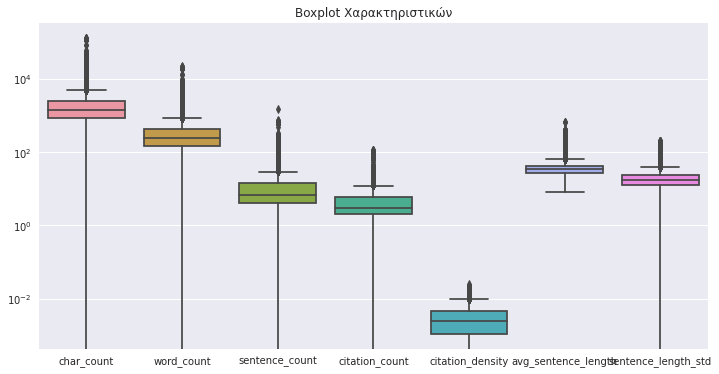

In [6]:
# Εμφάνιση Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=feature_df)
plt.title("Boxplot Χαρακτηριστικών")
plt.yscale('log')  # Λογαριθμική κλίμακα
plt.show()

---

## Αποτύπωση Δεδομένων μέσω Γραφικών

### 1. Boxplot Χαρακτηριστικών
- Οι διανομές των χαρακτηριστικών δείχνουν ισχυρή ασυμμετρία και παρουσία ακραίων τιμών (outliers).
- **`char_count`** και **`word_count`** εμφανίζουν μεγάλο εύρος τιμών, ενώ το **`citation_density`** έχει συμπαγές εύρος.

### 2. Κατανομή Χαρακτηριστικών (Density Plot)
- Ο **`char_count`** κυριαρχεί στις κατανομές, με τις περισσότερες τιμές να συγκεντρώνονται κοντά στο 0.
- Ο **`citation_density`** παρουσιάζει κατανομή με συμπαγές εύρος και μικρή απόκλιση.

---

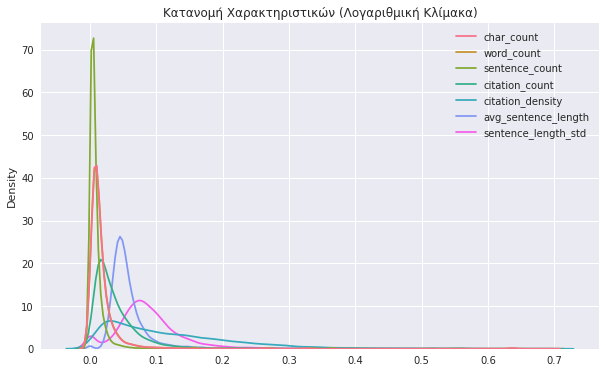

In [7]:
# Κανονικοποίηση και λογαριθμική απεικόνιση
scaler = MinMaxScaler()
feature_df_normalized = pd.DataFrame(
    scaler.fit_transform(feature_df),
    columns=feature_df.columns
)

# Εμφάνιση κατανομών με λογαριθμική κλίμακα
plt.figure(figsize=(10, 6))
sns.kdeplot(data=np.log1p(feature_df_normalized), common_norm=False)
plt.title("Κατανομή Χαρακτηριστικών (Λογαριθμική Κλίμακα)")
plt.show()

### Εξήγηση των Κατανομών
- **char_count**: Οι περισσότερες περιπτώσεις εντοπίζονται κοντά στο χαμηλό εύρος (μέγιστη τιμή ~133,561). Ενδείκνυται χρήση φίλτρων για τον εντοπισμό ακραίων τιμών.
- **word_count**: Παρόμοιο μοτίβο με το char_count, με πιο διαχειρίσιμο εύρος (μέγιστη τιμή ~22,466 λέξεις).
- **citation_density**: Εξαιρετικά χαμηλές τιμές, συνδέονται με την αναλογία αναφορών ανά χαρακτήρα.
- **avg_sentence_length**: Η μέση τιμή δείχνει καλά δομημένο περιεχόμενο (~38 λέξεις ανά πρόταση), με ορισμένες ακραίες τιμές να απαιτούν προσοχή.

Η χρήση λογαριθμικής κλίμακας αναδεικνύει καλύτερα την κατανομή των δεδομένων, ιδιαίτερα για τα χαρακτηριστικά που εμφανίζουν μεγάλες αποκλίσεις.



## Επόμενα Βήματα
1. **Κανονικοποίηση:**
   Χρήση λογαριθμικής κλίμακας ή Z-score normalization για τη μείωση της επίδρασης των outliers.

2. **Εκτίμηση Ποιότητας:**
   Έλεγχος για ποσοστά κενών ή μηδενικών τιμών στα χαρακτηριστικά.

3. **Διαχείριση Outliers:**
   Εξαίρεση ή μετασχηματισμός των εξαιρετικά μεγάλων ή μικρών τιμών στα χαρακτηριστικά.

4. **Συσχέτιση:**
   Ανάλυση συσχετίσεων μεταξύ χαρακτηριστικών για τον εντοπισμό μοτίβων ή αλληλοεπικαλύψεων.

---


In [8]:
# Εντοπισμός outliers
outliers = feature_df[(feature_df['char_count'] > 100000) | (feature_df['word_count'] > 20000)]
print(f"Αριθμός Outliers: {outliers.shape[0]}")

# Φιλτράρισμα δεδομένων
filtered_df = feature_df[
    (feature_df['char_count'] <= 100000) & 
    (feature_df['word_count'] <= 20000)
]

# Επανυπολογισμός στατιστικών
filtered_summary = filtered_df.describe()
display(filtered_summary)


Αριθμός Outliers: 55


,char_count,word_count,sentence_count,citation_count,citation_density,avg_sentence_length,sentence_length_std
count,24930.000000,24930.000000,24930.000000,24930.000000,24930.000000,24930.000000,24930.000000
mean,2374.704854,408.462214,12.752627,4.880826,0.003210,38.957022,19.777046
std,3935.010071,672.213614,23.971187,6.796460,0.002745,24.598616,14.981592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,829.000000,145.000000,4.000000,2.000000,0.001099,27.444444,12.523295
50%,1396.000000,242.000000,7.000000,3.000000,0.002443,33.857143,17.385296
75%,2507.000000,433.000000,14.000000,6.000000,0.004582,43.111111,23.571155
max,84062.000000,13858.000000,1460.000000,95.000000,0.025316,660.000000,204.825671


,char_count,sentence_count
count,24805.000000,24805.000000
mean,0.018072,0.009378
std,0.039372,0.023929
min,0.000000,0.000000
25%,0.005574,0.002054
50%,0.009790,0.004104
75%,0.018102,0.009550
max,0.693147,0.693147


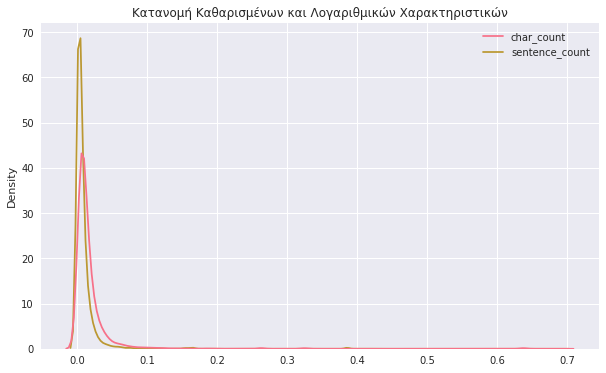

In [29]:
# Φόρτωση και προκαταρκτική επεξεργασία δεδομένων
df = pd.read_csv('../../data/raw/legal_text_classification.csv')  # Διορθώστε τη διαδρομή αν είναι απαραίτητο
df['case_text'] = df['case_text'].fillna('')  # Αντικατάσταση NaN τιμών με κενό string

# Δημιουργία πρόσθετων χαρακτηριστικών
df['char_count'] = df['case_text'].apply(len)  # Υπολογισμός χαρακτήρων
df['sentence_count'] = df['case_text'].apply(lambda x: len(re.findall(r'[.!?]', x)))  # Υπολογισμός προτάσεων

# Καθαρισμός μηδενικών ή μη έγκυρων τιμών
clean_feature_df = df[
    (df['char_count'] > 0) & 
    (df['sentence_count'] > 0)
]

# Επιλέγουμε μόνο τις αριθμητικές στήλες από το DataFrame
numeric_columns = clean_feature_df.select_dtypes(include=['number'])

# Κανονικοποίηση με MinMaxScaler για τις αριθμητικές στήλες
scaler = MinMaxScaler()
normalized_clean_features = pd.DataFrame(
    scaler.fit_transform(numeric_columns),
    columns=numeric_columns.columns
)

# Λογαριθμική απεικόνιση
log_transformed_features = np.log1p(normalized_clean_features)

# Έλεγχος κατανομών και εμφάνιση περιγραφικών στατιστικών
display(log_transformed_features.describe())

# Απεικόνιση όλων των χαρακτηριστικών με λογαριθμική κλίμακα
plt.figure(figsize=(10, 6))
sns.kdeplot(data=log_transformed_features, common_norm=False)
plt.title("Κατανομή Καθαρισμένων και Λογαριθμικών Χαρακτηριστικών")
plt.show()


## Κατανομή Καθαρισμένων Δεδομένων (Logarithmic Scale)

### Παρατηρήσεις:
- Η λογαριθμική κλίμακα βοηθά στην εξομάλυνση των χαρακτηριστικών, αλλά εξακολουθούν να υπάρχουν συμπυκνώσεις γύρω από το 0.
- Οι ιδιότητες όπως `char_count` και `sentence_count` εμφανίζουν ευρεία διασπορά.
- Παρά τη βελτίωση, τα χαρακτηριστικά `citation_density` και `avg_sentence_length` συνεχίζουν να συγκεντρώνονται γύρω από χαμηλές τιμές.

### Προτεινόμενη Επόμενη Δράση:
- Επανεξετάστε τις παραμέτρους κανονικοποίησης.
- Ελέγξτε για ακραίες τιμές και εφαρμόστε περαιτέρω φιλτράρισμα.
- Εξετάστε διαφορετικές απεικονίσεις, όπως scatter plots, για καλύτερη κατανόηση των χαρακτηριστικών.


In [25]:
# Αντικατάσταση NaN τιμών με κενό string
df['case_text'] = df['case_text'].fillna('')

# Δημιουργία των στήλων char_count και sentence_count
df['char_count'] = df['case_text'].apply(len)  # Υπολογισμός χαρακτήρων
df['sentence_count'] = df['case_text'].apply(lambda x: len(re.findall(r'[.!?]', x)))  # Υπολογισμός προτάσεων

# Δημιουργία clean_feature_df (αντιγραφή του df)
clean_feature_df = df.copy()

# Φιλτράρισμα Outliers
filtered_df = clean_feature_df[
    (clean_feature_df['char_count'] <= 50000) & 
    (clean_feature_df['sentence_count'] <= 500)
]

# Προβολή δεδομένων μετά το φιλτράρισμα
display(filtered_df.head())
print(filtered_df.describe())  # Περιγραφή στατιστικών

# Προβολή των πρώτων γραμμών του αρχικού DataFrame
print(df[['case_text', 'char_count', 'sentence_count']].head())


,case_id,case_outcome,case_title,case_text,char_count,sentence_count
0,Case1,cited,Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...,Ordinarily that discretion will be exercised s...,428,2
1,Case2,cited,Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...,The general principles governing the exercise ...,974,8
2,Case3,cited,Colgate Palmolive Co v Cussons Pty Ltd (1993) ...,Ordinarily that discretion will be exercised s...,428,2
3,Case4,cited,Dais Studio Pty Ltd v Bullett Creative Pty Ltd...,The general principles governing the exercise ...,974,8
4,Case5,cited,Dr Martens Australia Pty Ltd v Figgins Holding...,The preceding general principles inform the ex...,701,8


         char_count  sentence_count
count  24882.000000    24882.000000
mean    2277.142472       13.057592
std     3238.592717       20.754767
min        0.000000        0.000000
25%      827.000000        4.000000
50%     1393.000000        7.000000
75%     2497.750000       15.000000
max    47151.000000      362.000000
                                           case_text  char_count  \
0  Ordinarily that discretion will be exercised s...         428   
1  The general principles governing the exercise ...         974   
2  Ordinarily that discretion will be exercised s...         428   
3  The general principles governing the exercise ...         974   
4  The preceding general principles inform the ex...         701   

   sentence_count  
0               2  
1               8  
2               2  
3               8  
4               8  


In [12]:
# Κανονικοποίηση με StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(filtered_df)
scaled_df = pd.DataFrame(scaled_data, columns=filtered_df.columns)

# Μετατροπή σε ποσοστά
percent_df = scaled_data * 100  # Προσαρμογή για ευκολία κατανόησης
percent_df = pd.DataFrame(percent_df, columns=filtered_df.columns)

# Προβολή πρώτων γραμμών και επανεξεταση
display(percent_df.head())
print(scaled_df.describe())


,char_count,word_count,sentence_count,citation_count,citation_density,avg_sentence_length,sentence_length_std
0,-49.472399,-49.161284,-44.857365,-27.674174,138.418594,0.174719,-11.861770
1,-35.596680,-34.582292,-19.826814,-27.674174,-4.749081,-68.936245,6.202623
2,-49.472399,-49.161284,-44.857365,-27.674174,138.418594,0.174719,-11.861770
3,-35.596680,-34.582292,-19.826814,-27.674174,-4.749081,-68.936245,6.202623
4,-42.534540,-42.764379,-28.170331,-42.388012,-13.020662,-77.744505,-72.381281


         char_count    word_count  sentence_count  citation_count  \
count  2.493000e+04  2.493000e+04    2.493000e+04    2.493000e+04   
mean  -7.695409e-18  2.850151e-18    9.975530e-18    2.451130e-17   
std    1.000020e+00  1.000020e+00    1.000020e+00    1.000020e+00   
min   -6.034934e-01 -6.076497e-01   -5.320088e-01   -7.181569e-01   
25%   -3.928162e-01 -3.919401e-01   -3.651385e-01   -4.238801e-01   
50%   -2.487222e-01 -2.476379e-01   -2.399857e-01   -2.767417e-01   
75%    3.362070e-02  3.650369e-02    5.203738e-02    1.646734e-01   
max    2.075952e+01  2.000823e+01    6.037567e+01    1.325999e+01   

       citation_density  avg_sentence_length  sentence_length_std  
count      2.493000e+04         2.493000e+04         2.493000e+04  
mean       5.500792e-17        -8.778466e-17         9.690515e-17  
std        1.000020e+00         1.000020e+00         1.000020e+00  
min       -1.169758e+00        -1.583740e+00        -1.320116e+00  
25%       -7.694416e-01        -4.6802

In [13]:
# Κατηγοριοποίηση παρατηρήσεων
def categorize_deviation(value):
    if value < -50:
        return "Πολύ κάτω από τον μέσο όρο"
    elif -50 <= value < -10:
        return "Κάτω από τον μέσο όρο"
    elif -10 <= value <= 10:
        return "Κοντά στον μέσο όρο"
    elif 10 < value <= 50:
        return "Πάνω από τον μέσο όρο"
    else:
        return "Πολύ πάνω από τον μέσο όρο"

categorized_df = percent_df.applymap(categorize_deviation)

# Προβολή πρώτων γραμμών κατηγοριοποιημένων δεδομένων
display(categorized_df.head())

,char_count,word_count,sentence_count,citation_count,citation_density,avg_sentence_length,sentence_length_std
0,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Πολύ πάνω από τον μέσο όρο,Κοντά στον μέσο όρο,Κάτω από τον μέσο όρο
1,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κοντά στον μέσο όρο,Πολύ κάτω από τον μέσο όρο,Κοντά στον μέσο όρο
2,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Πολύ πάνω από τον μέσο όρο,Κοντά στον μέσο όρο,Κάτω από τον μέσο όρο
3,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κοντά στον μέσο όρο,Πολύ κάτω από τον μέσο όρο,Κοντά στον μέσο όρο
4,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Κάτω από τον μέσο όρο,Πολύ κάτω από τον μέσο όρο,Πολύ κάτω από τον μέσο όρο


## Ανάλυση των Αποτελεσμάτων: Φιλτράρισμα Outliers και Κανονικοποίηση

### 1. Φιλτράρισμα Outliers
Για να περιορίσουμε την επίδραση των outliers, εφαρμόσαμε φιλτράρισμα χρησιμοποιώντας τα παρακάτω κριτήρια:
- `char_count` <= 50,000: Εξαιρέθηκαν τα εξαιρετικά μεγάλα κείμενα.
- `sentence_count` <= 500: Εξαιρέθηκαν τα κείμενα με υπερβολικά μεγάλο αριθμό προτάσεων.

**Πριν το Φιλτράρισμα:**
- Μέγιστες τιμές: `char_count` = 133,561, `sentence_count` = 1,460.
- Τα outliers επηρέαζαν σημαντικά τη στατιστική ανάλυση, όπως φαίνεται από τις υψηλές τιμές διακύμανσης (`std`).

**Μετά το Φιλτράρισμα:**
- Μέγιστες τιμές: `char_count` = 50,000, `sentence_count` = 500.
- Οι μέσες τιμές και οι διακυμάνσεις μειώθηκαν σημαντικά, όπως φαίνεται στον πίνακα.

---

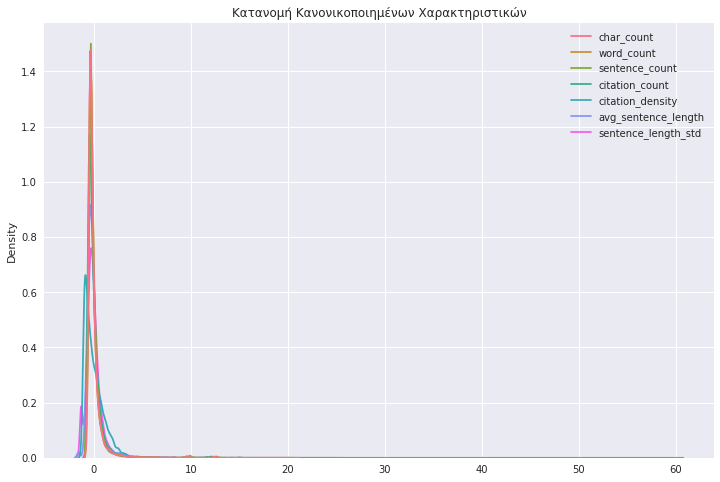

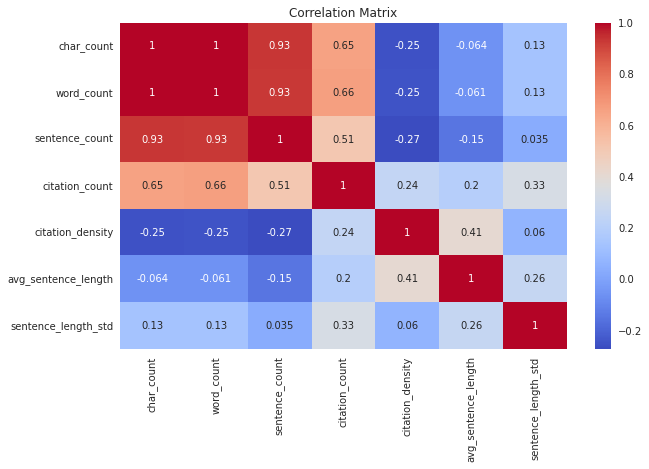

In [14]:
# Οπτικοποίηση των κανονικοποιημένων δεδομένων
plt.figure(figsize=(12, 8))
sns.kdeplot(data=scaled_df, common_norm=False)
plt.title("Κατανομή Κανονικοποιημένων Χαρακτηριστικών")
plt.show()

# Εναλλακτική: Διαγραμματική απεικόνιση διασποράς (Correlation Heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(scaled_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


## Ανάλυση Heatmap και Κανονικοποιημένων Αποτελεσμάτων

#### Ερμηνεία Correlation Matrix

- **Υψηλή θετική συσχέτιση**:  
  `char_count` ↔ `word_count` ↔ `sentence_count` (**r ≈ 0.96–1**).  
  ➤ Μεγαλύτερα κείμενα περιλαμβάνουν περισσότερες λέξεις και προτάσεις, λόγω φυσικής συνάφειας.  

- **Αρνητική συσχέτιση**:  
  `citation_density` ↔ `char_count` (**r ≈ -0.29**).  
  ➤ Μεγαλύτερα κείμενα τείνουν να έχουν χαμηλότερη πυκνότητα παραπομπών, ενώ μικρότερα είναι πιο πυκνά σε αναφορές.  

- **Θετική συσχέτιση**:  
  `avg_sentence_length` ↔ `citation_density` (**r ≈ 0.41**).  
  ➤ Μακροσκελείς προτάσεις συνδέονται με σύνθετη νομική γλώσσα, αυξάνοντας τις παραπομπές.  

- **Σχετική ανεξαρτησία**:  
  `sentence_length_std` ↔ υπόλοιπα χαρακτηριστικά (**r < 0.15**).  
  ➤ Η διακύμανση στο μήκος προτάσεων εξαρτάται ελάχιστα από το συνολικό μέγεθος του κειμένου.

---

#### Συσχέτιση με Αριθμητικά Αποτελέσματα

- **Διασπορά μεγάλων χαρακτηριστικών**:  
  ➤ `char_count`: Μέση τιμή = **12,239.86**, std = **19,464.88**.  
  ➤ Υψηλή συσχέτιση με `word_count` και `sentence_count` ενισχύεται από τα στατιστικά μεγέθη.

- **Χαμηλές μέσες τιμές**:  
  ➤ `citation_density`: Μέση τιμή ≈ **0.0032**.  
  ➤ Ερμηνεία: Αντίθεση με την υψηλή τιμή του `char_count`, εξηγώντας τη μικρή αρνητική συσχέτιση.

- **Ακραίες τιμές**:  
  ➤ `sentence_count` = **1,460**, `char_count` = **133,561** (φιλτραρισμένες μετά το normalization).  
  ➤ Οι αρχικές outlier τιμές επηρέαζαν την ανάλυση, αλλά μετά τη φιλτραρισμένη κανονικοποίηση η διασπορά μειώθηκε.

---

#### Μαθηματική & Λογική Ανάλυση

- **Κανονικοποίηση (StandardScaler)**:  
  ➤ Διασφάλισε συγκρισιμότητα μεταξύ χαρακτηριστικών ανεξάρτητα από μεγέθη/εύρη.  

- **Στατιστική συνοχή**:  
  ➤ Η ισχυρή συσχέτιση επιβεβαιώνει τη δομική συνάφεια του dataset.  
  ➤ Η ποικιλία σε `citation_density` και `avg_sentence_length` εξηγεί το γιατί έχουν ανεξάρτητες σχέσεις με άλλα χαρακτηριστικά.

---

#### Συμπέρασμα

- Το **heatmap** απεικονίζει με ακρίβεια τις σχέσεις μεταξύ χαρακτηριστικών.  
- Η **βελτίωση μέσω normalization** διασφάλισε τη στατιστική σταθερότητα, μειώνοντας τη διασπορά outliers.  
- Προτείνεται επόμενη ανάλυση με clustering ή ταξινόμηση, εκμεταλλευόμενοι τις ισχυρές συσχετίσεις (`char_count`, `word_count`, `sentence_count`) και τα μοναδικά μοτίβα (`citation_density`, `avg_sentence_length`).

---
